# 2025: Man Coverage vs. Defensive Efficiency

**Question:** In 2025, did defenses that played more **man coverage** tend to be more (or less) efficient?

Run each box with **Shift + Enter**, or everything at once with **Run All**. This takes a few seconds. The data comes from the `nfl_analytics` database, which `load_to_database.py` fills.

## Step 1 — Get the 2025 numbers from the database

We connect to your TiDB database using the same connection code as `load_to_database.py`, which reads the password from `.env`. Then we ask for three things for every 2025 team:
- **`man_pct`**: the share of pass plays where the defense played man coverage
- **`epa_per_play_allowed`**: defensive efficiency (lower is better)
- **`team`**: the team abbreviation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from load_to_database import connect

query = '''
SELECT team,
       man_coverage_rate * 100 AS man_pct,
       epa_per_play_allowed
FROM team_defense
WHERE season = 2025
'''
teams = pd.read_sql(query, connect("nfl_analytics"))
print(f"{len(teams)} teams loaded")
teams.sort_values("epa_per_play_allowed").round(3).head()

32 teams loaded


,team,man_pct,epa_per_play_allowed
12,HOU,31.461,-0.131
27,SEA,27.994,-0.116
14,JAX,23.796,-0.105
20,MIN,18.251,-0.099
7,CLE,40.780,-0.096


## Step 2 — Measure the trend

The **trend line** is the straight line that comes closest to all 32 dots. It's fitted with `np.polyfit`, which finds the best slope and starting point.

We also calculate the **correlation (r)**, which shows how tightly the dots follow that line. It runs from −1 to +1, and a value near 0 means there's no real relationship.

In [2]:
slope, intercept = np.polyfit(teams["man_pct"], teams["epa_per_play_allowed"], 1)
r = teams["man_pct"].corr(teams["epa_per_play_allowed"])

print(f"Slope: {slope:+.4f} EPA per play for each extra 1% of man coverage")
print(f"Correlation: r = {r:+.2f}  (explains {r**2:.0%} of the differences between defenses)")

Slope: -0.0001 EPA per play for each extra 1% of man coverage
Correlation: r = -0.00  (explains 0% of the differences between defenses)


## Step 3 — The chart

- **One dot per team.** Each dot is labeled with the team's abbreviation.
- **Better defenses are at the top.** Lower EPA allowed is better, so the vertical axis is flipped.
- **The gray line is the trend.** If man coverage helped, the line would rise to the right. If it hurt, the line would fall.

The chart is also saved to `figures/man_coverage_vs_efficiency_2025.png`.

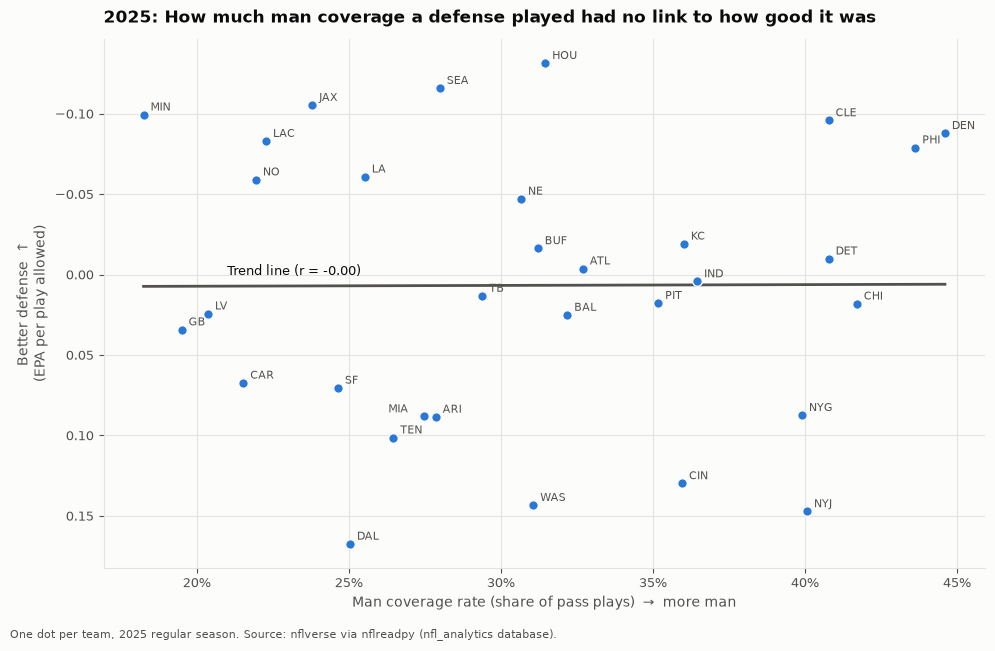

In [3]:
BLUE, INK, INK_2, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

fig, ax = plt.subplots(figsize=(10, 6.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

ax.scatter(teams["man_pct"], teams["epa_per_play_allowed"], s=48, color=BLUE,
           edgecolor=SURFACE, linewidth=1, zorder=3)
label_offsets = {"MIA": (-26, 3)}   # nudge labels that would overlap a neighbor
for _, row in teams.iterrows():
    ax.annotate(row["team"], (row["man_pct"], row["epa_per_play_allowed"]),
                xytext=label_offsets.get(row["team"], (5, 3)), textcoords="offset points",
                fontsize=8, color=INK_2)

xs = np.linspace(teams["man_pct"].min(), teams["man_pct"].max(), 50)
ax.plot(xs, slope * xs + intercept, color=INK_2, linewidth=2, zorder=2)
ax.annotate(f"Trend line (r = {r:+.2f})", (21, slope * 21 + intercept),
            xytext=(0, 8), textcoords="offset points", ha="left", fontsize=9, color=INK)

ax.invert_yaxis()   # lower EPA allowed = better defense, so put it at the top
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("Man coverage rate (share of pass plays)  →  more man", color=INK_2)
ax.set_ylabel("Better defense  ↑\n(EPA per play allowed)", color=INK_2)
ax.grid(True, color=GRID, linewidth=0.8, zorder=0)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=INK_2, labelsize=9)

ax.set_title("2025: How much man coverage a defense played had no link to how good it was",
             loc="left", fontsize=12, fontweight="bold", color=INK, pad=12)
fig.text(0.01, 0.01, "One dot per team, 2025 regular season. Source: nflverse via nflreadpy (nfl_analytics database).",
         fontsize=8, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/man_coverage_vs_efficiency_2025.png", dpi=200, facecolor=SURFACE)
plt.show()

**How to read it:** the trend line is almost flat, and the dots are scattered evenly around it. Some of the best defenses played lots of man (Denver, Philadelphia), and others played almost none (Minnesota, Jacksonville). The worst defenses are just as mixed. In 2025, the **type** of coverage didn't separate good defenses from bad ones.